## Loading the Data

In [ ]:
!git clone https://github.com/k3rnel-pan1c-ksd/input-sounds.git

Cloning into 'input-sounds'...
remote: Enumerating objects: 10256, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 10256 (delta 5), reused 1 (delta 0), pack-reused 10238 (from 3)
Receiving objects: 100% (10256/10256), 520.82 MiB | 15.44 MiB/s, done.
Resolving deltas: 100% (10/10), done.
Updating files: 100% (10264/10264), done.


In [ ]:
import os
import random
from pathlib import Path

import numpy as np
import librosa
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_DIR = Path("../input-sounds/cropped_base_pretraining")

CLASSES = list("abcdefghijklmnopqrstuvwxyz")
CLASS_TO_IDX = {key: i for i, key in enumerate(CLASSES)}

SAMPLE_RATE = 44100
N_SAMPLES = 11025
N_FFT = 1024
HOP_LENGTH = 225
N_MELS = 64

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [ ]:
waveforms = []
labels = []
filenames = []

for key in CLASSES:
    for i in range(1, 126):
        path = DATA_DIR / f"{key}_{i}.wav"

        if not path.exists():
            continue

        audio, sr = librosa.load(path, sr=None, mono=True)

        if sr != SAMPLE_RATE:
            audio = librosa.resample(
                audio, orig_sr=sr, target_sr=SAMPLE_RATE
            )

        if len(audio) < N_SAMPLES:
            audio = np.pad(audio, (0, N_SAMPLES - len(audio)))
        else:
            audio = audio[:N_SAMPLES]

        waveforms.append(audio.astype(np.float32))
        labels.append(CLASS_TO_IDX[key])
        filenames.append(str(path))

waveforms = np.stack(waveforms)
labels = np.array(labels, dtype=np.int32)
filenames = np.array(filenames)

print("Waveforms:", waveforms.shape)
print("Labels:", labels.shape)
print("Number of classes:", len(np.unique(labels)))

Waveforms: (3250, 11025)
Labels: (3250,)
Number of classes: 26


In [ ]:
indices = np.arange(len(labels))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=labels[temp_idx]
)

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

Train: 2275
Validation: 487
Test: 488


Important limitation: These recordings may share the same keyboard, environment, and recording session. A random split measures within-session generalization, not necessarily performance on a new recording setup.

In [ ]:
def extract_features(audio):
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SAMPLE_RATE,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        pad_mode="constant"
    )

    log_mel = librosa.power_to_db(mel, ref=np.max)

    return log_mel.astype(np.float32)


X = np.stack([
    extract_features(audio)
    for audio in waveforms
])

X = X[..., np.newaxis]

print("Features:", X.shape)

Features: (3250, 64, 50, 1)


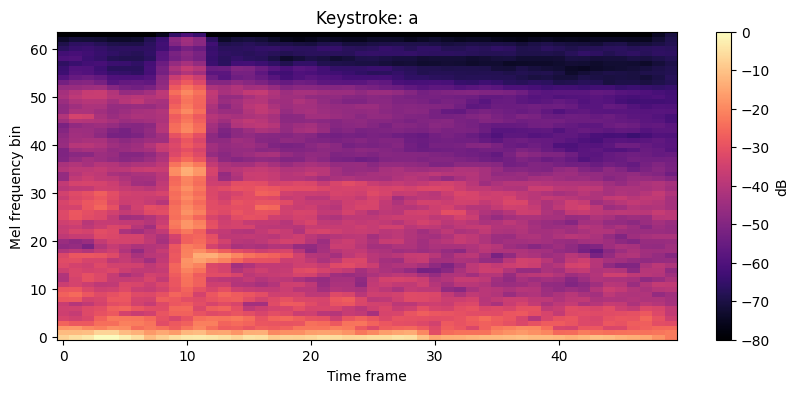

In [ ]:
plt.figure(figsize=(10, 4))

plt.imshow(
    X[0, :, :, 0],
    aspect="auto",
    origin="lower",
    cmap="magma"
)

plt.title(f"Keystroke: {CLASSES[labels[0]]}")
plt.xlabel("Time frame")
plt.ylabel("Mel frequency bin")
plt.colorbar(label="dB")
plt.show()

## Fitting the CNN

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def build_cnn():
    model = keras.Sequential([
        keras.Input(shape=(64, 50, 1)),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.2),

        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),

        layers.Flatten(),

        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.4),

        layers.Dense(len(CLASSES), activation="softmax")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


model = build_cnn()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 62, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 22, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 29, 22, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 9, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 9, 128)     │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 490,778 (1.87 MB)

 Trainable params: 490,074 (1.87 MB)

 Non-trainable params: 704 (2.75 KB)

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    keras.callbacks.ModelCheckpoint(
        "../artifacts/models/keystroke_cnn_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    X[train_idx],
    labels[train_idx],

    validation_data=(
        X[val_idx],
        labels[val_idx]
    ),

    epochs=30,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 23s 151ms/step - accuracy: 0.3609 - loss: 2.2845 - val_accuracy: 0.0637 - val_loss: 4.2497
Epoch 2/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8246 - loss: 0.7638 - val_accuracy: 0.0554 - val_loss: 2.9139
Epoch 3/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9499 - loss: 0.3052 - val_accuracy: 0.2731 - val_loss: 2.2817
Epoch 4/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9776 - loss: 0.1684 - val_accuracy: 0.4867 - val_loss: 1.5934
Epoch 5/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9903 - loss: 0.1060 - val_accuracy: 0.8316 - val_loss: 0.6821
Epoch 6/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9965 - loss: 0.0642 - val_accuracy: 0.9302 - val_loss: 0.3728
Epoch 7/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9965 - loss: 0.0511 - val_accuracy: 0.9938 - val_loss: 0.0877
Epoch 8/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9978 - loss: 0.0399 - val_accuracy: 0.9959 - val_l

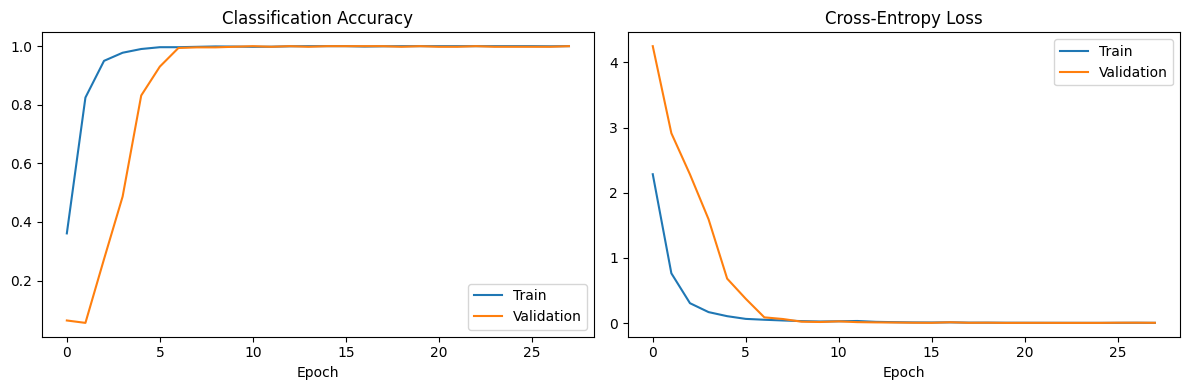

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Classification Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Cross-Entropy Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(
    X[test_idx],
    labels[test_idx],
    verbose=0
)

print(f"Test accuracy: {test_acc:.2%}")

predictions = model.predict(X[test_idx], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

print(classification_report(
    labels[test_idx],
    predicted_labels,
    target_names=CLASSES,
    zero_division=0
))

Test accuracy: 100.00%
              precision    recall  f1-score   support

           a       1.00      1.00      1.00        18
           b       1.00      1.00      1.00        19
           c       1.00      1.00      1.00        19
           d       1.00      1.00      1.00        19
           e       1.00      1.00      1.00        19
           f       1.00      1.00      1.00        19
           g       1.00      1.00      1.00        19
           h       1.00      1.00      1.00        19
           i       1.00      1.00      1.00        19
           j       1.00      1.00      1.00        19
           k       1.00      1.00      1.00        19
           l       1.00      1.00      1.00        18
           m       1.00      1.00      1.00        19
           n       1.00      1.00      1.00        18
           o       1.00      1.00      1.00        19
           p       1.00      1.00      1.00        18
           q       1.00      1.00      1.00        18
    

In [ ]:
import json

model.save("../artifacts/models/keystroke_cnn.keras")

np.savez_compressed(
    "../artifacts/models/keystroke_dataset.npz",
    waveforms=waveforms,
    labels=labels,
    filenames=filenames,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

config = {
    "classes": CLASSES,
    "sample_rate": SAMPLE_RATE,
    "n_samples": N_SAMPLES,
    "n_fft": N_FFT,
    "hop_length": HOP_LENGTH,
    "n_mels": N_MELS,
    "feature_type": "librosa log-mel power spectrogram",
    "db_reference": "per-sample maximum",
    "input_shape": [64, 50, 1]
}

with open("../artifacts/models/preprocessing_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Saved model, dataset, and preprocessing configuration.")

Saved model, dataset, and preprocessing configuration.


## Reloading model

In [ ]:

import json
import numpy as np
import tensorflow as tf
import librosa

# ------------------------------------
# 1. Load the saved CNN
# ------------------------------------

model = tf.keras.models.load_model(
    "../artifacts/models/keystroke_cnn.keras",
    compile=False
)

print("Model loaded successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

# ------------------------------------
# 2. Load the saved dataset
# ------------------------------------

with np.load("../artifacts/models/keystroke_dataset.npz", allow_pickle=False) as data:
    waveforms = data["waveforms"]
    labels = data["labels"]
    filenames = data["filenames"]

    train_idx = data["train_idx"]
    val_idx = data["val_idx"]
    test_idx = data["test_idx"]

print("\nDataset loaded successfully.")
print("Waveforms:", waveforms.shape)
print("Labels:", labels.shape)
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

# ------------------------------------
# 3. Load preprocessing configuration
# ------------------------------------

with open("../artifacts/models/preprocessing_config.json", "r") as f:
    config = json.load(f)

print("\nConfiguration loaded successfully.")
print(config)

classes = config["classes"]

# ------------------------------------
# 4. Recreate the original preprocessing
# ------------------------------------

def extract_features(audio):
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=config["sample_rate"],
        n_fft=config["n_fft"],
        hop_length=config["hop_length"],
        n_mels=config["n_mels"]
    )

    log_mel = librosa.power_to_db(
        mel,
        ref=np.max
    )

    return log_mel.astype(np.float32)

# ------------------------------------
# 5. Validate file compatibility
# ------------------------------------

assert waveforms.ndim == 2
assert waveforms.shape[1] == config["n_samples"]
assert len(waveforms) == len(labels)
assert model.output_shape[-1] == len(classes)

assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

assert len(train_idx) + len(val_idx) + len(test_idx) == len(labels)

print("\nAll compatibility checks passed.")

# ------------------------------------
# 6. Run inference on one test example
# ------------------------------------

idx = int(test_idx[0])

audio = waveforms[idx]
true_label = classes[int(labels[idx])]

features = extract_features(audio)
features = features[np.newaxis, ..., np.newaxis]

assert tuple(features.shape[1:]) == tuple(model.input_shape[1:])

predictions = model(features, training=False).numpy()[0]

predicted_idx = int(np.argmax(predictions))
predicted_label = classes[predicted_idx]
confidence = float(predictions[predicted_idx])

print("\nInference test:")
print("Original file:", filenames[idx])
print("True label:", true_label)
print("Predicted label:", predicted_label)
print(f"Confidence: {confidence:.2%}")

# ------------------------------------
# 7. Re-evaluate the entire test split
# ------------------------------------

X_test = np.stack([
    extract_features(waveforms[i])
    for i in test_idx
])[..., np.newaxis]

test_predictions = model.predict(
    X_test,
    batch_size=32,
    verbose=0
)

test_accuracy = np.mean(
    np.argmax(test_predictions, axis=1) == labels[test_idx]
)

print(f"\nReloaded model test accuracy: {test_accuracy:.2%}")


Model loaded successfully.
Input shape: (None, 64, 50, 1)
Output shape: (None, 26)

Dataset loaded successfully.
Waveforms: (3250, 11025)
Labels: (3250,)
Train: 2275
Validation: 487
Test: 488

Configuration loaded successfully.
{'classes': ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z'], 'sample_rate': 44100, 'n_samples': 11025, 'n_fft': 1024, 'hop_length': 225, 'n_mels': 64, 'feature_type': 'librosa log-mel power spectrogram', 'db_reference': 'per-sample maximum', 'input_shape': [64, 50, 1]}

All compatibility checks passed.

Inference test:
Original file: input-sounds/cropped_base_pretraining/h_113.wav
True label: h
Predicted label: h
Confidence: 99.84%

Reloaded model test accuracy: 100.00%


In [ ]:

import json
import numpy as np
import librosa
import tensorflow as tf
import matplotlib.pyplot as plt

with open("../artifacts/models/preprocessing_config.json") as f:
    config = json.load(f)

model = tf.keras.models.load_model(
    "../artifacts/models/keystroke_cnn.keras",
    compile=False
)
model.trainable = False

with np.load("../artifacts/models/keystroke_dataset.npz", allow_pickle=False) as data:
    waveforms = data["waveforms"]
    labels = data["labels"]
    test_idx = data["test_idx"]

SR = config["sample_rate"]
N_FFT = config["n_fft"]
HOP = config["hop_length"]
N_MELS = config["n_mels"]

# Use librosa's filter-bank coefficients, but convert them to
# a constant TensorFlow tensor for differentiable matrix multiplication.
mel_filters = librosa.filters.mel(
    sr=SR,
    n_fft=N_FFT,
    n_mels=N_MELS
).astype(np.float32)

MEL_FILTERS = tf.constant(mel_filters.T)

# Explicit periodic Hann window, consistent with librosa's STFT.
def hann_window(frame_length, dtype):
    return tf.signal.hann_window(
        frame_length,
        periodic=True,
        dtype=dtype
    )


def tf_power_to_db(mel):
    amin = tf.constant(1e-10, dtype=tf.float32)

    log_spec = 10.0 * (
        tf.math.log(tf.maximum(mel, amin))
        / tf.math.log(tf.constant(10.0, tf.float32))
    )

    # librosa ref=np.max is computed from the
    # original power spectrogram.
    ref_value = tf.reduce_max(
        mel,
        axis=[1, 2],
        keepdims=True
    )

    log_ref = 10.0 * (
        tf.math.log(tf.maximum(ref_value, amin))
        / tf.math.log(tf.constant(10.0, tf.float32))
    )

    log_spec = log_spec - log_ref

    # librosa's default top_db=80
    max_db = tf.reduce_max(
        log_spec,
        axis=[1, 2],
        keepdims=True
    )

    return tf.maximum(log_spec, max_db - 80.0)

def tf_log_mel(audio):
    """
    audio: [batch, samples], float32
    returns: [batch, 64, 50, 1]
    """
    audio = tf.convert_to_tensor(audio, dtype=tf.float32)

    # Match librosa STFT center=True and pad_mode="reflect".
    pad = N_FFT // 2
    audio = tf.pad(
        audio,
        [[0, 0], [pad, pad]],
        mode="CONSTANT"
    )

    stft = tf.signal.stft(
        audio,
        frame_length=N_FFT,
        frame_step=HOP,
        fft_length=N_FFT,
        window_fn=hann_window,
        pad_end=False
    )

    power = tf.square(tf.abs(stft))

    # [batch, frames, frequencies]
    #     × [frequencies, mel bands]
    # -> [batch, frames, mel bands]
    mel = tf.matmul(power, MEL_FILTERS)

    # librosa.power_to_db:
    # 10 * log10(max(power, amin) / max(ref, amin))
    amin = tf.constant(1e-10, dtype=tf.float32)

    log_power = 10.0 * (
        tf.math.log(tf.maximum(mel, amin))
        / tf.math.log(tf.constant(10.0, tf.float32))
    )

    # Per-example reference: np.max
    reference = tf.reduce_max(
        log_power,
        axis=[1, 2],
        keepdims=True
    )

    log_mel = log_power - reference

    # Match librosa's top_db=80
    maximum = tf.reduce_max(
        log_mel,
        axis=[1, 2],
        keepdims=True
    )

    log_mel = tf_power_to_db(mel)

    # CNN expects [batch, mel bands, time frames, channels].
    log_mel = tf.transpose(log_mel, [0, 2, 1])
    log_mel = log_mel[..., tf.newaxis]

    return log_mel


Librosa shape: (8, 64, 50)
TensorFlow shape: (8, 64, 50)
Mean absolute error: 5.2827595e-06
Maximum absolute error: 0.00016021729


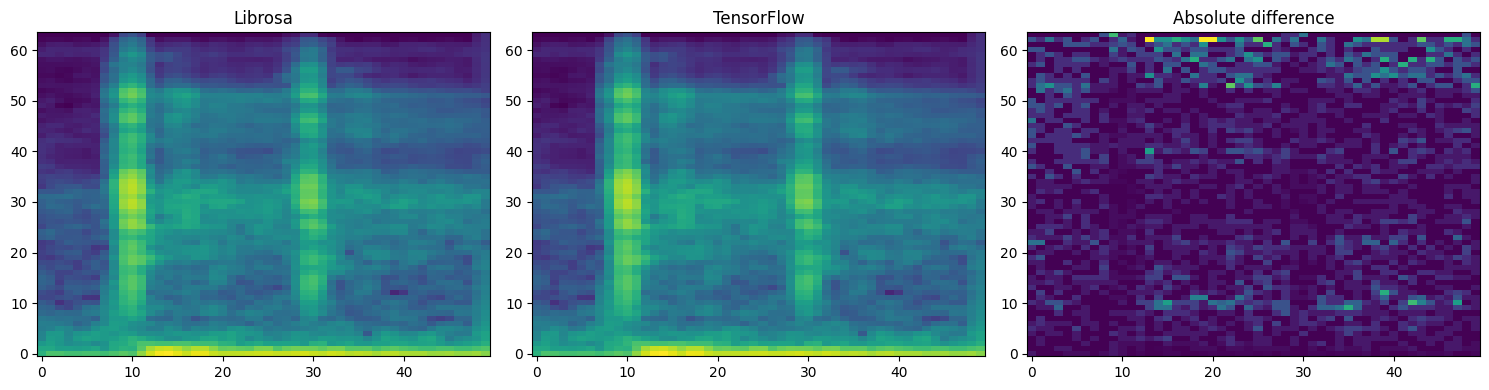

In [9]:

def librosa_log_mel(audio):
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SR,
        n_fft=N_FFT,
        hop_length=HOP,
        n_mels=N_MELS,
        pad_mode="constant"
    )

    return librosa.power_to_db(
        mel,
        ref=np.max
    ).astype(np.float32)


# Select a few held-out examples.
audio_batch = waveforms[test_idx[:8]]

librosa_features = np.stack([
    librosa_log_mel(x)
    for x in audio_batch
])

tf_features = tf_log_mel(audio_batch).numpy()[..., 0]

print("Librosa shape:", librosa_features.shape)
print("TensorFlow shape:", tf_features.shape)

difference = np.abs(
    librosa_features - tf_features
)

print("Mean absolute error:", difference.mean())
print("Maximum absolute error:", difference.max())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(
    librosa_features[0],
    aspect="auto",
    origin="lower",
    vmin=-80,
    vmax=0
)
axes[0].set_title("Librosa")

axes[1].imshow(
    tf_features[0],
    aspect="auto",
    origin="lower",
    vmin=-80,
    vmax=0
)
axes[1].set_title("TensorFlow")

axes[2].imshow(
    difference[0],
    aspect="auto",
    origin="lower"
)
axes[2].set_title("Absolute difference")

plt.tight_layout()
plt.show()


In [10]:

librosa_input = librosa_features[..., np.newaxis]
tf_input = tf_log_mel(audio_batch)

pred_librosa = model(
    librosa_input,
    training=False
).numpy()

pred_tf = model(
    tf_input,
    training=False
).numpy()

print(
    "Predictions match:",
    np.array_equal(
        np.argmax(pred_librosa, axis=1),
        np.argmax(pred_tf, axis=1)
    )
)

print(
    "Maximum probability difference:",
    np.max(np.abs(pred_librosa - pred_tf))
)

for i in range(len(audio_batch)):
    print(
        f"Sample {i}: "
        f"librosa={np.argmax(pred_librosa[i])}, "
        f"tensorflow={np.argmax(pred_tf[i])}"
    )


Predictions match: True
Maximum probability difference: 2.1827873e-09
Sample 0: librosa=7, tensorflow=7
Sample 1: librosa=20, tensorflow=20
Sample 2: librosa=4, tensorflow=4
Sample 3: librosa=18, tensorflow=18
Sample 4: librosa=2, tensorflow=2
Sample 5: librosa=14, tensorflow=14
Sample 6: librosa=3, tensorflow=3
Sample 7: librosa=23, tensorflow=23


In [11]:

audio = tf.Variable(
    waveforms[test_idx[:1]],
    dtype=tf.float32
)

target = tf.constant(
    labels[test_idx[:1]],
    dtype=tf.int32
)

with tf.GradientTape() as tape:
    features = tf_log_mel(audio)

    probabilities = model(
        features,
        training=False
    )

    loss = tf.keras.losses.sparse_categorical_crossentropy(
        target,
        probabilities
    )

    loss = tf.reduce_mean(loss)

gradient = tape.gradient(loss, audio)

print("Loss:", float(loss))
print("Gradient exists:", gradient is not None)

if gradient is not None:
    print("Gradient shape:", gradient.shape)
    print(
        "Gradient norm:",
        float(tf.norm(gradient))
    )
    print(
        "All gradients finite:",
        bool(tf.reduce_all(tf.math.is_finite(gradient)))
    )


Loss: 0.0016495682066306472
Gradient exists: True
Gradient shape: (1, 11025)
Gradient norm: 1.131171464920044
All gradients finite: True


In [12]:

# Error statistics by sample
for i in range(len(audio_batch)):
    diff = difference[i]

    print(
        f"Sample {i}: "
        f"MAE={diff.mean():.6f}, "
        f"Max={diff.max():.6f}, "
        f"95th percentile={np.percentile(diff, 95):.6f}"
    )

# Locate the largest discrepancy
sample_idx, mel_idx, frame_idx = np.unravel_index(
    np.argmax(difference),
    difference.shape
)

print("\nLargest discrepancy:")
print("Sample:", sample_idx)
print("Mel bin:", mel_idx)
print("Time frame:", frame_idx)
print("Librosa:", librosa_features[sample_idx, mel_idx, frame_idx])
print("TensorFlow:", tf_features[sample_idx, mel_idx, frame_idx])

# How many bins differ substantially?
for threshold in [0.01, 0.1, 1.0, 5.0, 10.0]:
    percentage = np.mean(difference > threshold) * 100
    print(f"Error > {threshold} dB: {percentage:.3f}%")


Sample 0: MAE=0.000005, Max=0.000061, 95th percentile=0.000015
Sample 1: MAE=0.000006, Max=0.000114, 95th percentile=0.000023
Sample 2: MAE=0.000005, Max=0.000099, 95th percentile=0.000019
Sample 3: MAE=0.000006, Max=0.000160, 95th percentile=0.000023
Sample 4: MAE=0.000005, Max=0.000092, 95th percentile=0.000011
Sample 5: MAE=0.000006, Max=0.000107, 95th percentile=0.000019
Sample 6: MAE=0.000005, Max=0.000114, 95th percentile=0.000019
Sample 7: MAE=0.000005, Max=0.000099, 95th percentile=0.000015

Largest discrepancy:
Sample: 3
Mel bin: 62
Time frame: 31
Librosa: -79.05904
TensorFlow: -79.0592
Error > 0.01 dB: 0.000%
Error > 0.1 dB: 0.000%
Error > 1.0 dB: 0.000%
Error > 5.0 dB: 0.000%
Error > 10.0 dB: 0.000%


## Adversary Attack

In [13]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

model.trainable = False

# Convert data into TensorFlow datasets
BATCH_SIZE = 32

train_dataset = tf.data.Dataset.from_tensor_slices((
    waveforms[train_idx].astype(np.float32),
    labels[train_idx].astype(np.int32)
))

train_dataset = (
    train_dataset
    .shuffle(len(train_idx), seed=42)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_dataset = tf.data.Dataset.from_tensor_slices((
    waveforms[test_idx].astype(np.float32),
    labels[test_idx].astype(np.int32)
))

test_dataset = (
    test_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

In [14]:
EPSILON = 0.01
STEP_SIZE = 0.001
EPOCHS = 30

N_SAMPLES = waveforms.shape[1]

delta = tf.Variable(
    tf.zeros((N_SAMPLES,), dtype=tf.float32),
    trainable=True
)

print("Perturbation shape:", delta.shape)

Perturbation shape: (11025,)


In [15]:

loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=False
)

@tf.function
def uap_train_step(audio_batch, label_batch):
    with tf.GradientTape() as tape:
        # Apply the same perturbation to all waveforms
        perturbed = audio_batch + delta[tf.newaxis, :]

        # Keep audio within valid waveform amplitude bounds
        perturbed = tf.clip_by_value(
            perturbed, -1.0, 1.0
        )

        # Differentiable preprocessing
        features = tf_log_mel(perturbed)

        # Frozen classifier
        predictions = model(
            features,
            training=False
        )

        # Maximize classification loss
        loss = loss_fn(label_batch, predictions)

    gradient = tape.gradient(loss, delta)

    # Sign-gradient ascent
    delta.assign_add(
        STEP_SIZE * tf.sign(gradient)
    )

    # Project back into the L-infinity constraint
    delta.assign(
        tf.clip_by_value(
            delta, -EPSILON, EPSILON
        )
    )

    return loss


In [16]:
loss_history = []

for epoch in range(EPOCHS):
    epoch_losses = []

    for audio_batch, label_batch in train_dataset:
        loss = uap_train_step(
            audio_batch,
            label_batch
        )

        epoch_losses.append(float(loss))

    mean_loss = np.mean(epoch_losses)
    loss_history.append(mean_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} "
        f"- Loss: {mean_loss:.4f}"
    )

Epoch 01/30 - Loss: 183.3659
Epoch 02/30 - Loss: 327.8492
Epoch 03/30 - Loss: 358.8796
Epoch 04/30 - Loss: 378.5471
Epoch 05/30 - Loss: 389.8448
Epoch 06/30 - Loss: 397.5863
Epoch 07/30 - Loss: 405.6367
Epoch 08/30 - Loss: 407.6255
Epoch 09/30 - Loss: 411.0661
Epoch 10/30 - Loss: 417.5475
Epoch 11/30 - Loss: 419.2849
Epoch 12/30 - Loss: 415.7216
Epoch 13/30 - Loss: 420.9837
Epoch 14/30 - Loss: 424.3064
Epoch 15/30 - Loss: 426.2047
Epoch 16/30 - Loss: 425.9817
Epoch 17/30 - Loss: 427.9000
Epoch 18/30 - Loss: 430.2570
Epoch 19/30 - Loss: 429.0407
Epoch 20/30 - Loss: 432.5343
Epoch 21/30 - Loss: 432.0244
Epoch 22/30 - Loss: 434.8062
Epoch 23/30 - Loss: 436.7843
Epoch 24/30 - Loss: 435.8842
Epoch 25/30 - Loss: 436.7817
Epoch 26/30 - Loss: 434.3670
Epoch 27/30 - Loss: 437.2786
Epoch 28/30 - Loss: 438.2430
Epoch 29/30 - Loss: 438.4254
Epoch 30/30 - Loss: 438.9924


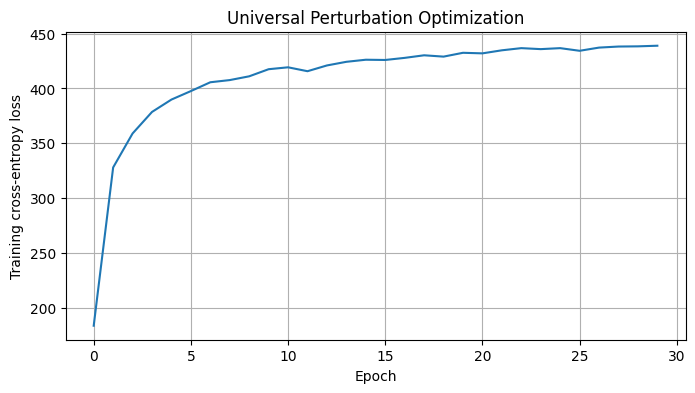

In [17]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training cross-entropy loss")
plt.title("Universal Perturbation Optimization")
plt.grid(True)
plt.show()

In [18]:
def evaluate_perturbation(dataset, perturbation=None):
    total_correct = 0
    total_loss = 0.0
    total_samples = 0

    for audio_batch, label_batch in dataset:
        if perturbation is not None:
            audio_batch = tf.clip_by_value(
                audio_batch + perturbation[tf.newaxis, :],
                -1.0,
                1.0
            )

        features = tf_log_mel(audio_batch)

        predictions = model(
            features,
            training=False
        )

        batch_losses = tf.keras.losses.sparse_categorical_crossentropy(
            label_batch,
            predictions
        )

        predicted_labels = tf.argmax(
            predictions,
            axis=1,
            output_type=tf.int32
        )

        total_correct += int(
            tf.reduce_sum(
                tf.cast(
                    predicted_labels == label_batch,
                    tf.int32
                )
            )
        )

        total_loss += float(
            tf.reduce_sum(batch_losses)
        )

        total_samples += int(tf.shape(audio_batch)[0])

    return {
        "accuracy": total_correct / total_samples,
        "loss": total_loss / total_samples
    }


clean_results = evaluate_perturbation(test_dataset)
uap_results = evaluate_perturbation(test_dataset, delta)

print("Clean:", clean_results)
print("UAP:", uap_results)

Clean: {'accuracy': 1.0, 'loss': 0.0038827923126518726}
UAP: {'accuracy': 0.0389344262295082, 'loss': 432.147955222208}


In [19]:
rng = np.random.default_rng(42)

random_noise = rng.uniform(
    -EPSILON,
    EPSILON,
    size=N_SAMPLES
).astype(np.float32)

random_noise = tf.constant(random_noise)

random_results = evaluate_perturbation(
    test_dataset,
    random_noise
)

print("\nComparison")
print(f"Clean accuracy:  {clean_results['accuracy']:.2%}")
print(f"Random accuracy: {random_results['accuracy']:.2%}")
print(f"UAP accuracy:    {uap_results['accuracy']:.2%}")


Comparison
Clean accuracy:  100.00%
Random accuracy: 67.21%
UAP accuracy:    3.89%


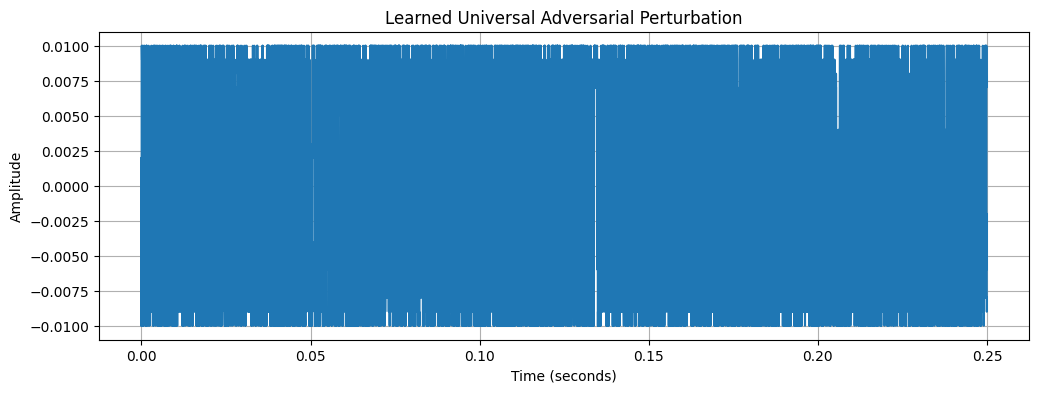

Maximum amplitude: 0.01
RMS amplitude: 0.008130321


In [20]:
delta_np = delta.numpy()

time_axis = np.arange(len(delta_np)) / SR

plt.figure(figsize=(12, 4))
plt.plot(time_axis, delta_np)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Learned Universal Adversarial Perturbation")
plt.grid(True)
plt.show()

print("Maximum amplitude:", np.max(np.abs(delta_np)))
print("RMS amplitude:", np.sqrt(np.mean(delta_np ** 2)))

In [21]:
from IPython.display import Audio, display

display(Audio(delta_np, rate=SR, normalize=False))

In [22]:
sample_idx = test_idx[0]

original = waveforms[sample_idx]
perturbed = np.clip(original + delta_np, -1.0, 1.0)

print("Original:")
display(Audio(original, rate=SR, normalize=False))

print("Perturbed:")
display(Audio(perturbed, rate=SR, normalize=False))

Original:


Perturbed:


In [ ]:
np.save("../artifacts/masks/uap_epsilon_001.npy", delta.numpy())

# Reload it
loaded_delta = np.load("../artifacts/masks/uap_epsilon_001.npy")

print("Shape:", loaded_delta.shape)
print("Maximum amplitude:", np.max(np.abs(loaded_delta)))
print("Matches original:", np.allclose(loaded_delta, delta.numpy()))

import soundfile as sf

sf.write(
    "../artifacts/masks/uap_epsilon_001.wav",
    delta.numpy(),
    SR,
    subtype="FLOAT"
)

Shape: (11025,)
Maximum amplitude: 0.01
Matches original: True


In [23]:
from collections import Counter

all_predictions = []
all_true_labels = []

for audio_batch, label_batch in test_dataset:
    perturbed = tf.clip_by_value(
        audio_batch + delta[tf.newaxis, :],
        -1.0, 1.0
    )

    probabilities = model(
        tf_log_mel(perturbed),
        training=False
    )

    predictions = tf.argmax(
        probabilities, axis=1
    ).numpy()

    all_predictions.extend(predictions)
    all_true_labels.extend(label_batch.numpy())

counts = Counter(all_predictions)

print("Most common predicted classes:")
for idx, count in counts.most_common(10):
    print(
        f"{config['classes'][idx]}: "
        f"{count} predictions"
    )

print("Number of distinct predicted classes:", len(counts))

Most common predicted classes:
h: 488 predictions
Number of distinct predicted classes: 1


In [24]:
rng = np.random.default_rng(123)

uap_rms = np.sqrt(np.mean(delta.numpy() ** 2))

random_waveform = rng.normal(
    size=delta.shape
).astype(np.float32)

random_waveform /= np.sqrt(
    np.mean(random_waveform ** 2)
)

random_waveform *= uap_rms

# Check its peak amplitude.
print("Random RMS:", np.sqrt(np.mean(random_waveform ** 2)))
print("Random peak:", np.max(np.abs(random_waveform)))

Random RMS: 0.008130321
Random peak: 0.03193941


In [25]:
rng = np.random.default_rng(123)

uap = delta.numpy()

shuffled_noise = rng.permutation(uap).astype(np.float32)

print("UAP RMS:", np.sqrt(np.mean(uap ** 2)))
print("Shuffled RMS:", np.sqrt(np.mean(shuffled_noise ** 2)))

print("UAP peak:", np.max(np.abs(uap)))
print("Shuffled peak:", np.max(np.abs(shuffled_noise)))

shuffled_results = evaluate_perturbation(
    test_dataset,
    tf.constant(shuffled_noise)
)

print("Shuffled noise accuracy:", shuffled_results["accuracy"])

UAP RMS: 0.008130321
Shuffled RMS: 0.008130322
UAP peak: 0.01
Shuffled peak: 0.01
Shuffled noise accuracy: 0.5163934426229508


In [27]:
b_idx = config["classes"].index("h")

b_probabilities = []

for audio_batch, _ in test_dataset:
    perturbed = tf.clip_by_value(
        audio_batch + delta[tf.newaxis, :],
        -1.0, 1.0
    )

    predictions = model(
        tf_log_mel(perturbed),
        training=False
    ).numpy()

    b_probabilities.extend(predictions[:, b_idx])

b_probabilities = np.array(b_probabilities)

print("Mean P(b):", b_probabilities.mean())
print("Median P(b):", np.median(b_probabilities))
print("Min P(b):", b_probabilities.min())
print("Max P(b):", b_probabilities.max())

Mean P(b): 1.0
Median P(b): 1.0
Min P(b): 1.0
Max P(b): 1.0
